# 05 — Report Figures from the Confirmatory Evidence and the Saved Notebook Outputs

**Project:** Fraud Detection Under Limited Review Capacity: A Temporally Validated Study of Tree-Based and Neural Models and Decision Policies
**Programme / module:** MSc Data Science and Its Applications, University of Greenwich — COMP1885 Individual Project
**GitHub Issue:** [#230](https://github.com/chathuranga-sudusinghe/fraud-detection-review-capacity/issues/230)
**Notebook status:** reporting. No model is trained or scored, and no raw, processed or row-level data is read.

This notebook produces the figures of the COMP1885 report from committed code, so that each figure can be traced to its source and regenerated. It reads only:

- the promoted aggregate evidence of the single confirmatory run `2026-11-01T104408Z` (`evidence/confirmatory/2026-11-01T104408Z/records/`);
- the saved outputs of notebooks 01 and 03, whose charts are exported byte for byte.

Notebooks 01–04 stay unchanged as saved evidence: they are neither edited nor rerun ([notebook index](README.md)).

Each run writes the figures and a manifest with the Secure Hash Algorithm, 256-bit (SHA-256) checksum of every figure and source file to a dated, gitignored directory `outputs/report_figures/<UTC time>/`.

## 1. Setup

In [1]:
import base64
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUN_ID = "2026-11-01T104408Z"
RECORDS = ROOT / "evidence" / "confirmatory" / RUN_ID / "records"
NB01 = ROOT / "notebooks" / "01_dataset_feasibility_audit.ipynb"
NB03 = ROOT / "notebooks" / "03_merged_dataset_inspection.ipynb"
OUT = ROOT / "outputs" / "report_figures" / datetime.now(timezone.utc).strftime("%Y-%m-%dT%H%M%SZ")
OUT.mkdir(parents=True, exist_ok=False)

TREE, NEURAL, REFERENCE = "#2a7ad5", "#eb6a34", "#7f7f7f"
plt.rcParams.update({"font.size": 10, "font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
MANIFEST = {"run_id": RUN_ID, "matplotlib": matplotlib.__version__, "figures": []}


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def record(name, path, sources, note):
    MANIFEST["figures"].append({
        "figure": name,
        "file": Path(path).name,
        "sha256": sha256(path),
        "sources": [{"file": str(Path(s).relative_to(ROOT)), "sha256": sha256(s)} for s in sources],
        "note": note,
    })
    display(Image(filename=str(path), width=720))


print("output directory:", OUT.relative_to(ROOT))

output directory: outputs/report_figures/2026-11-20T123912Z


## 2. Charts saved in notebooks 01 and 03

The image stored in the notebook output is written unchanged: the chart is located by the title in its cell's source, and its bytes are decoded from the saved output.

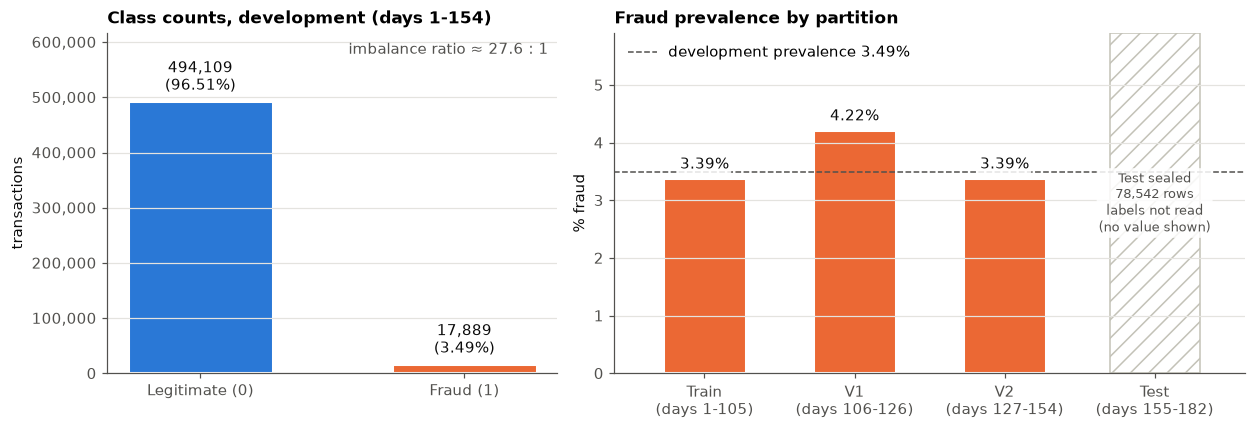

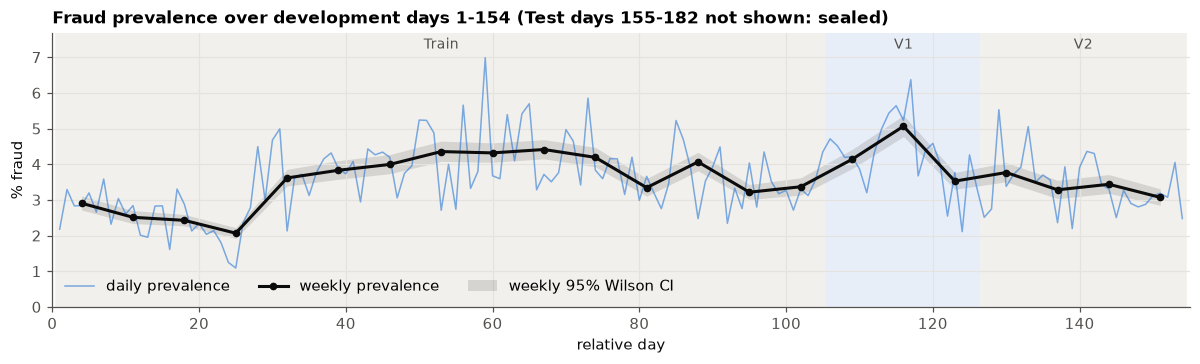

In [2]:
def saved_png(notebook, title):
    nb = json.loads(notebook.read_text(encoding="utf-8"))
    found = []
    for cell in nb["cells"]:
        if cell["cell_type"] == "code" and title in "".join(cell["source"]):
            found += [o["data"]["image/png"] for o in cell.get("outputs", []) if "image/png" in o.get("data", {})]
    assert len(found) == 1, f"expected one saved chart for {title!r}, found {len(found)}"
    return base64.b64decode(found[0])


for name, notebook, title, file in [
    ("class balance and prevalence by partition", NB03, "Class counts, development", "fig_class_balance_nb03.png"),
    ("daily fraud prevalence over the development days", NB01, "Fraud prevalence over development days", "fig_daily_prevalence_nb01.png"),
]:
    path = OUT / file
    path.write_bytes(saved_png(notebook, title))
    record(name, path, [notebook], f"saved output of {notebook.name}, exported unchanged")

## 3. Recall@2% of each configuration on Test

Pooled Recall@2% under the daily top-K policy R3 at K = 56 (K: fixed daily review budget), with its 95 % interval, from each configuration's `test_evaluation` record. The dashed line is the perfect-ranker (oracle) ceiling of the same record.

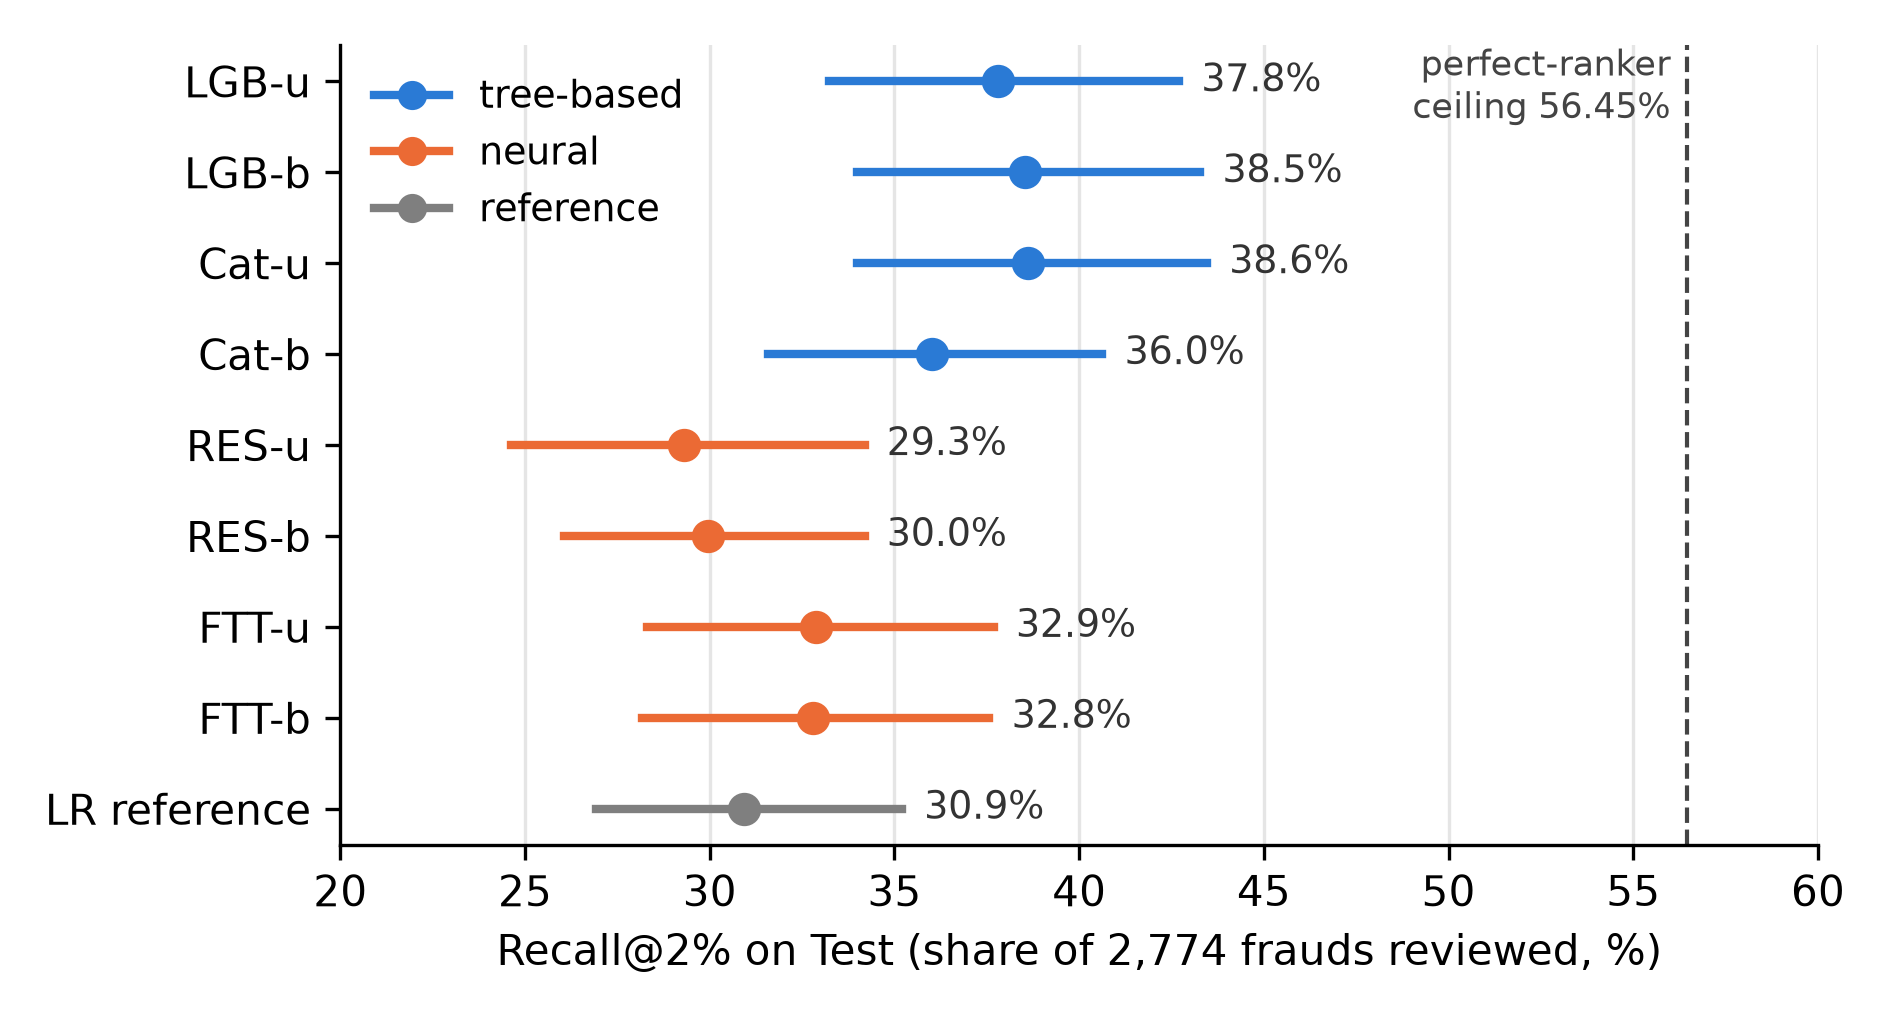

In [3]:
CONFIGS = [("LGB-u", "T"), ("LGB-b", "T"), ("Cat-u", "T"), ("Cat-b", "T"),
           ("RES-u", "N"), ("RES-b", "N"), ("FTT-u", "N"), ("FTT-b", "N"), ("LR", "R")]
rows, sources, ceilings = [], [], set()
for name, family in CONFIGS:
    path = RECORDS / f"test_evaluation-{name}.json"
    entry = [e for e in json.loads(path.read_text())["r3"] if e["capacity"] == 0.02][0]
    assert entry["k"] == 56 and entry["counts"]["frauds"] == 2774
    interval = entry["intervals"]["recall"]
    assert interval["level"] == 0.95
    rows.append((name, entry["metrics"]["recall"], interval["lower"], interval["upper"], family))
    ceilings.add(round(entry["metrics"]["oracle_ceiling"], 12))
    sources.append(path)
assert len(ceilings) == 1
ceiling = ceilings.pop()

fig, ax = plt.subplots(figsize=(6.3, 3.4), dpi=300)
colour = {"T": TREE, "N": NEURAL, "R": REFERENCE}
for i, (name, recall, lower, upper, family) in enumerate(rows):
    y = len(rows) - 1 - i
    ax.plot([lower * 100, upper * 100], [y, y], color=colour[family], lw=2)
    ax.plot(recall * 100, y, "o", color=colour[family], ms=7)
    ax.text(upper * 100 + 0.6, y, f"{recall * 100:.1f}%", va="center", fontsize=9, color="#333")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([("LR reference" if r[0] == "LR" else r[0]) for r in rows][::-1])
ax.axvline(ceiling * 100, ls="--", color="#444", lw=1)
ax.text(ceiling * 100 - 0.45, len(rows) - 0.6, f"perfect-ranker\nceiling {ceiling * 100:.2f}%", ha="right", va="top", fontsize=8.5, color="#444")
ax.set_xlim(20, 60)
ax.set_xlabel("Recall@2% on Test (share of 2,774 frauds reviewed, %)")
ax.grid(axis="x", color="#e5e5e5")
ax.legend(handles=[Line2D([], [], color=TREE, marker="o", lw=2, label="tree-based"),
                   Line2D([], [], color=NEURAL, marker="o", lw=2, label="neural"),
                   Line2D([], [], color=REFERENCE, marker="o", lw=2, label="reference")],
          loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
path = OUT / "fig_recall_by_configuration.png"
fig.savefig(path)
plt.close(fig)
record("Recall@2% of each configuration on Test", path, sources, "R3 at K = 56; 95% intervals from the evaluation records")

## 4. Daily R2 alert demand of LGB-b against the budget

Alerts per Test day of the 2 % rate threshold R2 set on Validation 2, for the H3 configuration LGB-b, against K = 56, from the `test_workload` record. The totals are checked against the record before the chart is drawn.

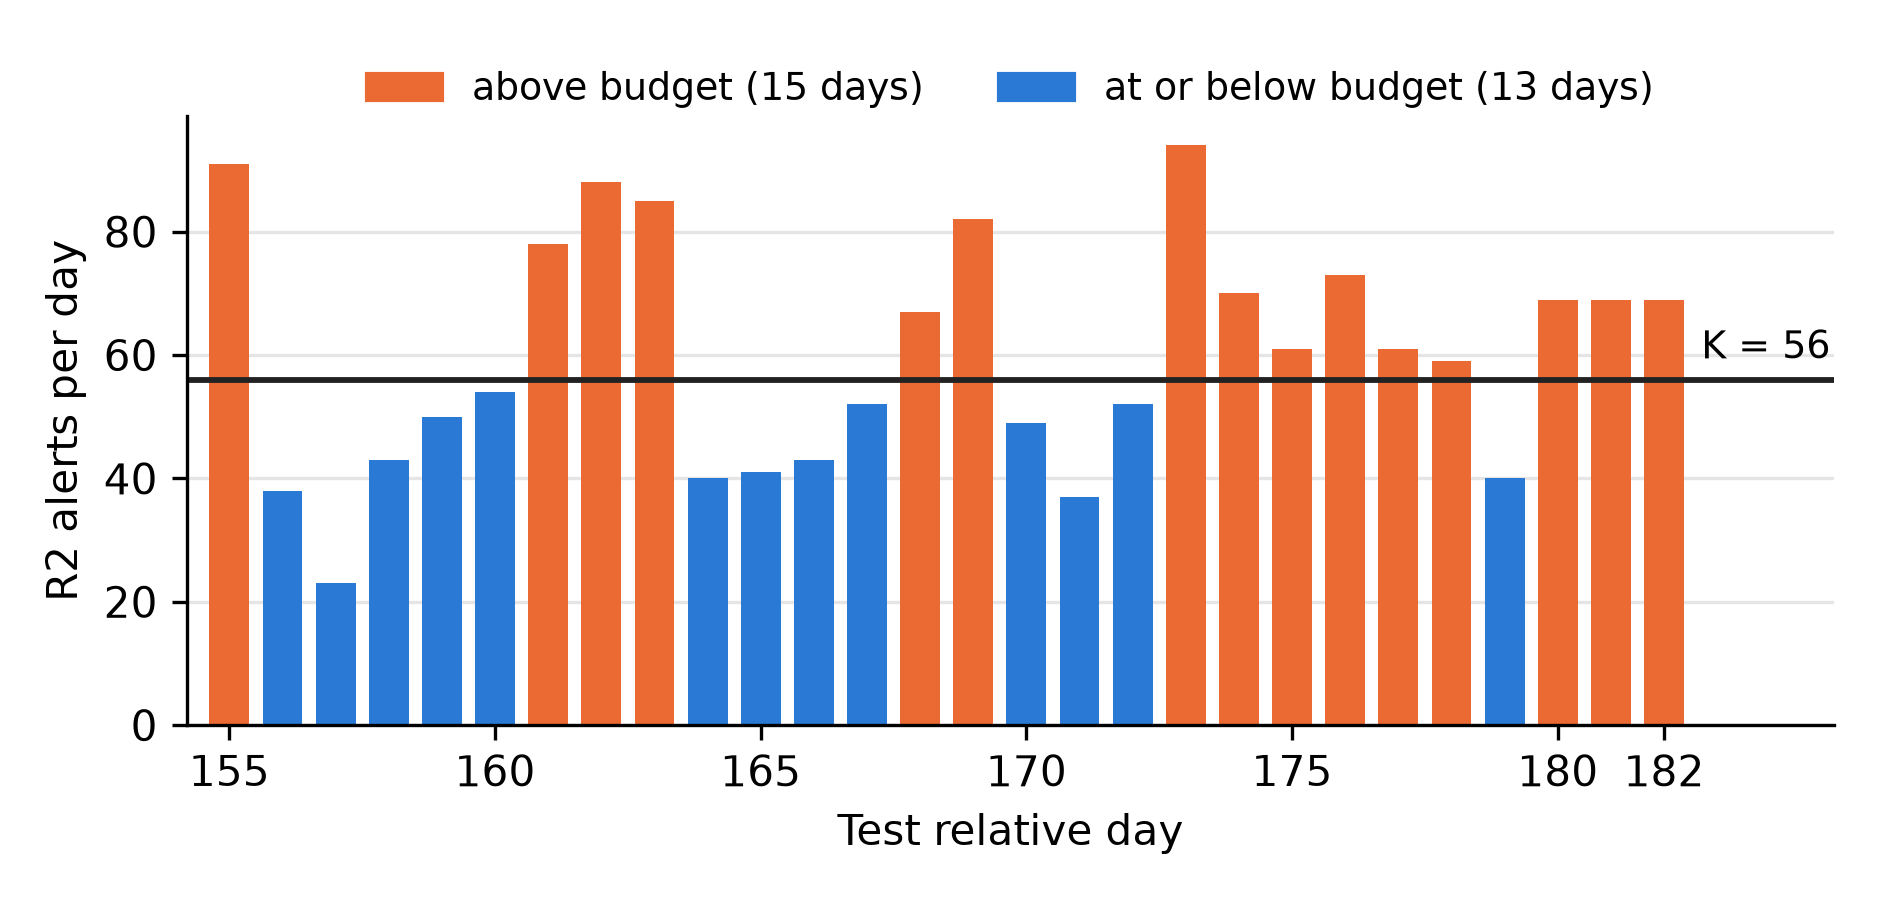

In [4]:
path_src = RECORDS / "test_workload-LGB-b.json"
entry = [e for e in json.loads(path_src.read_text())["entries"] if e["capacity"] == 0.02][0]
K, fidelity = entry["k"], entry["fidelity"]
days = [t["day"] for t in fidelity["terms"]]
alerts = [t["alerts"] for t in fidelity["terms"]]
assert K == 56 and len(days) == 28
assert sum(max(a - K, 0) for a in alerts) == fidelity["total_overflow"]
assert sum(max(K - a, 0) for a in alerts) == fidelity["total_unused"]
above = sum(a > K for a in alerts)
assert above == fidelity["days_above_budget"]

fig, ax = plt.subplots(figsize=(6.3, 3.0), dpi=300)
ax.bar(days, alerts, color=[NEURAL if a > K else TREE for a in alerts], width=0.75)
ax.axhline(K, color="#222", lw=1.4)
ax.text(days[-1] + 0.7, K + 2, f"K = {K}", va="bottom", fontsize=9)
ax.set_xlabel("Test relative day")
ax.set_ylabel("R2 alerts per day")
ax.set_xlim(days[0] - 0.8, days[-1] + 3.2)
ax.set_xticks([155, 160, 165, 170, 175, 180, 182])
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=NEURAL, label=f"above budget ({above} days)"),
                   Patch(color=TREE, label=f"at or below budget ({len(days) - above} days)")],
          loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=2, frameon=False, fontsize=9)
fig.tight_layout()
path = OUT / "fig_daily_alerts_vs_budget.png"
fig.savefig(path)
plt.close(fig)
record("daily R2 alert demand of LGB-b against K", path, [path_src],
       f"overflow {fidelity['total_overflow']}, unused {fidelity['total_unused']}, {above} of {len(days)} days above K")

## 5. Manifest

In [5]:
(OUT / "manifest.json").write_text(json.dumps(MANIFEST, indent=2) + "\n", encoding="utf-8")
for f in MANIFEST["figures"]:
    print(f["file"], f["sha256"][:16])

fig_class_balance_nb03.png 2ff9f2250e88b890
fig_daily_prevalence_nb01.png 51555077f2430c1c
fig_recall_by_configuration.png 9073d7ab03d4b708
fig_daily_alerts_vs_budget.png 01544cec5bcea914
